# My exploration
I start with distributions, then compare booking lead time, service mix and patient returns. I use the same SQL views as the reporting pipeline.

In [1]:
from pathlib import Path
import sqlite3
import matplotlib.pyplot as plt
from dental_analytics.clean_and_refresh import BASE

database = sqlite3.connect(f"file:{BASE}/processed/dental_clinic.sqlite?mode=ro", uri=True)
database.row_factory = sqlite3.Row


def query(sql):
    """I show the rows returned by one exploratory query."""
    rows = [dict(row) for row in database.execute(sql)]
    for row in rows:
        print(row)
    return rows


## 1. Distributions
I check appointment outcomes and service counts before comparing rates. Counts tell me which categories are large enough to investigate.

{'Status': 'Cancelled', 'Appointments': 3562}
{'Status': 'Completed', 'Appointments': 34556}
{'Status': 'No-show', 'Appointments': 1882}


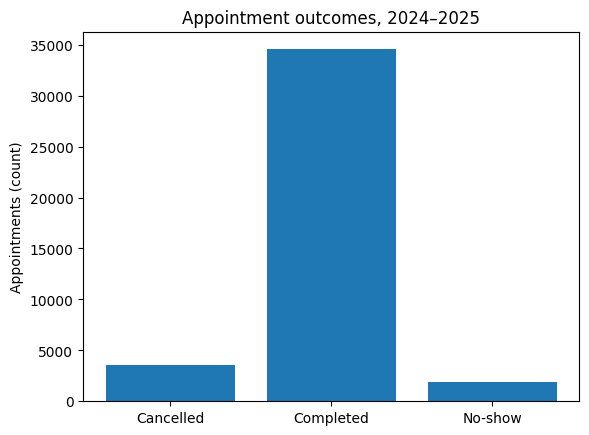

{'Care Category': 'Alignment, Jaw & Other Oral Care', 'Services': 2735}
{'Care Category': 'Gum & Supporting-Tissue Care', 'Services': 3560}
{'Care Category': 'Oral Surgery & Tooth Replacement', 'Services': 2290}
{'Care Category': 'Root Canal & Pulp Care', 'Services': 488}
{'Care Category': 'Routine & Preventive Care', 'Services': 19936}
{'Care Category': 'Tooth Repair & Restoration', 'Services': 8312}


In [2]:
outcomes = query("SELECT Status, COUNT(*) AS Appointments FROM appointments GROUP BY Status")
plt.bar([r["Status"] for r in outcomes], [r["Appointments"] for r in outcomes])
plt.ylabel("Appointments (count)")
plt.title("Appointment outcomes, 2024–2025")
plt.show()
services = query("SELECT [Care Category], COUNT(*) AS Services FROM treatments GROUP BY 1")


## 2. Booking lead time
I compare no-shows with completed plus missed visits, keeping cancellations outside the denominator. I inspect each branch before proposing a reminder pilot; the pattern alone does not prove a cause.

{'branch': 'Harbour', 'lead_time_band': '0-6 days', 'scheduled_appointments': 1769, 'completed_visits': 1577, 'no_shows': 41, 'cancelled_appointments': 151, 'eligible_appointments': 1618, 'no_show_rate': 0.02533992583436341}
{'branch': 'Harbour', 'lead_time_band': '7-29 days', 'scheduled_appointments': 3083, 'completed_visits': 2707, 'no_shows': 113, 'cancelled_appointments': 263, 'eligible_appointments': 2820, 'no_show_rate': 0.040070921985815605}
{'branch': 'Harbour', 'lead_time_band': '30+ days', 'scheduled_appointments': 1834, 'completed_visits': 1548, 'no_shows': 128, 'cancelled_appointments': 158, 'eligible_appointments': 1676, 'no_show_rate': 0.07637231503579953}
{'branch': 'Meadow', 'lead_time_band': '0-6 days', 'scheduled_appointments': 1747, 'completed_visits': 1516, 'no_shows': 40, 'cancelled_appointments': 191, 'eligible_appointments': 1556, 'no_show_rate': 0.02570694087403599}
{'branch': 'Meadow', 'lead_time_band': '7-29 days', 'scheduled_appointments': 3157, 'completed_vi

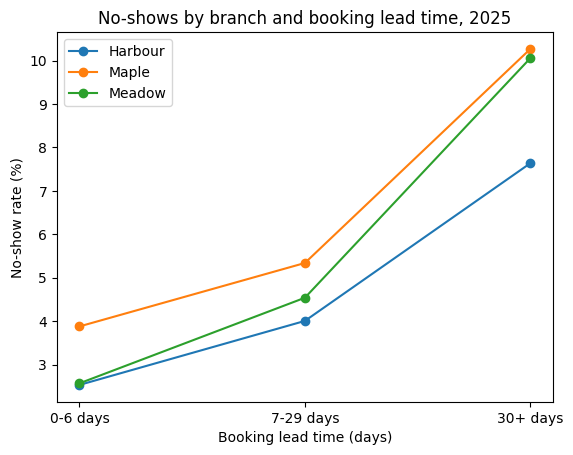

In [3]:
lead_time = query("SELECT * FROM noshow_by_lead_time")
bands = ["0-6 days", "7-29 days", "30+ days"]
for branch in sorted({row["branch"] for row in lead_time}):
    branch_rows = {row["lead_time_band"]: row for row in lead_time if row["branch"] == branch}
    plt.plot(
        bands,
        [100 * branch_rows[band]["no_show_rate"] for band in bands],
        marker="o",
        label=branch,
    )
plt.ylabel("No-show rate (%)")
plt.xlabel("Booking lead time (days)")
plt.title("No-shows by branch and booking lead time, 2025")
plt.legend()
plt.show()


## 3. Revenue bridge
I separate changes in service counts from changes in average charges. I investigate the root-canal decline because it explains a large share of the revenue fall.

{'care_category': 'Alignment, Jaw & Other Oral Care', 'services_2024': 1334, 'services_2025': 1401, 'net_revenue_2024_cad': 359512.82, 'net_revenue_2025_cad': 369846.24, 'average_charge_2024_cad': 269.4999, 'average_charge_2025_cad': 263.9873, 'revenue_change_cad': 10333.42, 'volume_effect_cad': 18056.49, 'price_effect_cad': -7723.07, 'rounding_difference_cad': -0.0}
{'care_category': 'Gum & Supporting-Tissue Care', 'services_2024': 1795, 'services_2025': 1765, 'net_revenue_2024_cad': 432329.94, 'net_revenue_2025_cad': 426537.49, 'average_charge_2024_cad': 240.8523, 'average_charge_2025_cad': 241.6643, 'revenue_change_cad': -5792.45, 'volume_effect_cad': -7225.57, 'price_effect_cad': 1433.12, 'rounding_difference_cad': 0.0}
{'care_category': 'Oral Surgery & Tooth Replacement', 'services_2024': 1150, 'services_2025': 1140, 'net_revenue_2024_cad': 317265.09, 'net_revenue_2025_cad': 311234.59, 'average_charge_2024_cad': 275.8827, 'average_charge_2025_cad': 273.0128, 'revenue_change_cad': 

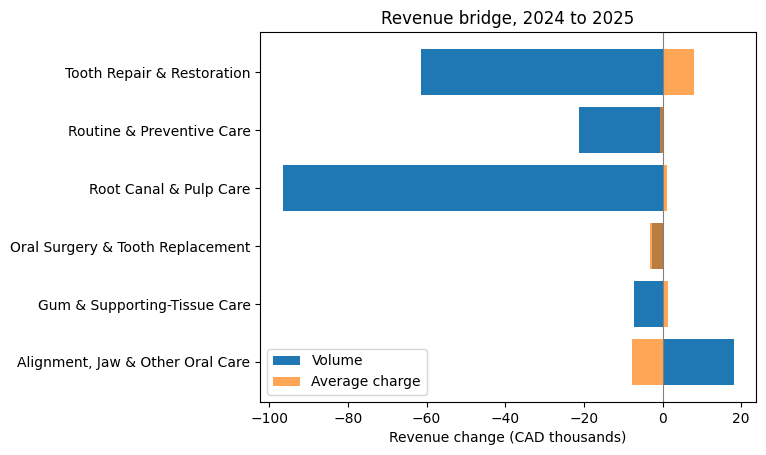

In [4]:
bridge = query("SELECT * FROM revenue_bridge")
labels = [row["care_category"] for row in bridge]
plt.barh(labels, [row["volume_effect_cad"] / 1000 for row in bridge], label="Volume")
plt.barh(
    labels, [row["price_effect_cad"] / 1000 for row in bridge], label="Average charge", alpha=0.7
)
plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel("Revenue change (CAD thousands)")
plt.title("Revenue bridge, 2024 to 2025")
plt.legend()
plt.show()


## 4. Return cohorts
I group patients by first-visit quarter and require a complete follow-up window. I leave immature cohorts blank instead of treating unobserved returns as failures.

{'first_visit_quarter': '2024-Q1', 'patients': 564, 'eligible_6_month_patients': 564, 'returned_6_month_patients': 518, 'return_rate_6_months': 0.9184397163120568, 'eligible_12_month_patients': 564, 'returned_12_month_patients': 538, 'return_rate_12_months': 0.9539007092198581}
{'first_visit_quarter': '2024-Q2', 'patients': 584, 'eligible_6_month_patients': 584, 'returned_6_month_patients': 483, 'return_rate_6_months': 0.827054794520548, 'eligible_12_month_patients': 584, 'returned_12_month_patients': 540, 'return_rate_12_months': 0.9246575342465754}
{'first_visit_quarter': '2024-Q3', 'patients': 569, 'eligible_6_month_patients': 569, 'returned_6_month_patients': 402, 'return_rate_6_months': 0.7065026362038664, 'eligible_12_month_patients': 569, 'returned_12_month_patients': 502, 'return_rate_12_months': 0.8822495606326889}
{'first_visit_quarter': '2024-Q4', 'patients': 562, 'eligible_6_month_patients': 562, 'returned_6_month_patients': 323, 'return_rate_6_months': 0.5747330960854092, 

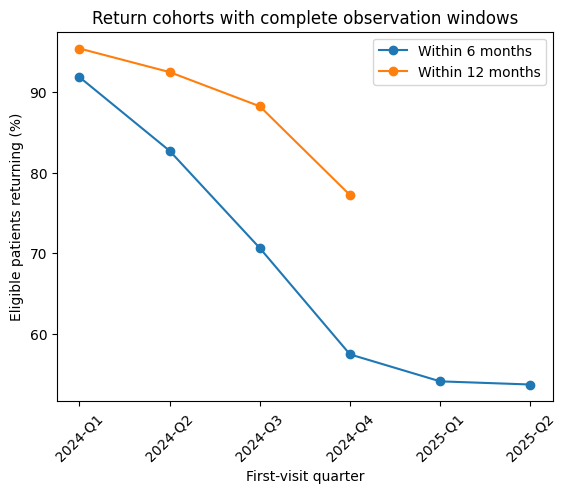

{'channel': 'Community', 'patients': 502, 'eligible_12_month_patients': 119, 'returned_12_month_patients': 104, 'return_rate_12_months': 0.8739495798319328, 'net_revenue_cad': 425120.4, 'revenue_per_patient_cad': 846.85, 'first_12_month_revenue_per_eligible_patient_cad': 915.57}
{'channel': 'Existing practice', 'patients': 4820, 'eligible_12_month_patients': 1072, 'returned_12_month_patients': 956, 'return_rate_12_months': 0.8917910447761194, 'net_revenue_cad': 4164627.49, 'revenue_per_patient_cad': 864.03, 'first_12_month_revenue_per_eligible_patient_cad': 974.87}
{'channel': 'Organic search', 'patients': 1204, 'eligible_12_month_patients': 282, 'returned_12_month_patients': 250, 'return_rate_12_months': 0.8865248226950354, 'net_revenue_cad': 1010931.66, 'revenue_per_patient_cad': 839.64, 'first_12_month_revenue_per_eligible_patient_cad': 935.47}
{'channel': 'Referral', 'patients': 2169, 'eligible_12_month_patients': 512, 'returned_12_month_patients': 447, 'return_rate_12_months': 0.8

In [5]:
cohorts = query("SELECT * FROM retention_cohorts")
quarters = [row["first_visit_quarter"] for row in cohorts]
for window in [6, 12]:
    rates = [
        (
            100 * row[f"return_rate_{window}_months"]
            if row[f"return_rate_{window}_months"] is not None
            else float("nan")
        )
        for row in cohorts
    ]
    plt.plot(quarters, rates, marker="o", label=f"Within {window} months")
plt.ylabel("Eligible patients returning (%)")
plt.xlabel("First-visit quarter")
plt.xticks(rotation=45)
plt.title("Return cohorts with complete observation windows")
plt.legend()
plt.show()
channels = query("SELECT * FROM channel_value")
database.close()


## My next step
I use these analyses to rank a reminder pilot, a root-canal booking review and collections work. I keep estimated opportunities separate from achieved results; the calculations and actions refresh in FINDINGS.md.